# Data Modeling for Analytics (Star Schemas)

Operational databases are normalised for safe writes (Lesson 02). Analytics needs something else: simple, fast queries over history. **Dimensional modelling** (Ralph Kimball) organises analytical data into **fact tables** (events and their numbers) and **dimension tables** (descriptive context). Arranged together, they form a **star schema**.

**After this lesson you can:**

1. Identify facts, dimensions, measures and the grain of a fact table.
2. Build a star schema from the normalised Chinook data.
3. Create a date dimension and explain surrogate keys.
4. Compare query complexity and speed with the normalised schema.
5. Explain slowly changing dimensions (SCD type 2).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sqlalchemy import create_engine, text

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets                                   # course helper: downloads and loads the sample data

engine = create_engine(datasets.ensure_chinook())  # starts PostgreSQL in Docker and loads Chinook on first use

def q(sql: str, **params) -> pd.DataFrame:
    """Run a SQL query and return the result as a DataFrame."""
    with engine.connect() as conn:
        return pd.read_sql(text(sql), conn, params=params)

lab = create_engine(datasets.POSTGRES_URL.format(db="course"))   # a separate database for experiments

def run(sql: str) -> None:
    """Execute SQL statements (DDL/DML) in the lab database, in one transaction."""
    with lab.begin() as conn:
        if "$$" in sql:                       # function bodies contain ";" -> send the whole script at once
            conn.execute(text(sql))
            return
        for stmt in [s for s in sql.split(";") if s.strip()]:
            conn.execute(text(stmt))

def lq(sql: str, **params) -> pd.DataFrame:
    with lab.connect() as conn:
        return pd.read_sql(text(sql), conn, params=params)

## 1. Facts, Dimensions and Grain

| Concept | Meaning | Chinook star schema |
| :--- | :--- | :--- |
| **grain** | what one fact row represents | one track sold on one invoice line |
| **fact table** | events with numeric **measures** | `fact_sales(quantity, revenue)` |
| **dimension** | descriptive attributes to filter and group by | `dim_customer`, `dim_track`, `dim_date`, `dim_employee` |
| **surrogate key** | an integer key created by the warehouse | `customer_key` (independent of the source id) |

Declare the grain first; every other decision follows from it.

## 2. Build the Star Schema

The source tables live in the `chinook` database; the warehouse is built in the `course` database, in a schema called `dw`. To move data between the databases, the cell reads with pandas and writes with `to_sql`, a small **ETL** job (M11 covers ETL properly).

In [2]:
run("DROP SCHEMA IF EXISTS dw CASCADE; CREATE SCHEMA dw")

dim_customer = q("""
SELECT c.customer_id AS customer_source_id, c.first_name || ' ' || c.last_name AS customer_name,
       c.city, c.country, coalesce(c.company, '(private)') AS company,
       e.first_name || ' ' || e.last_name AS support_rep
FROM customer c LEFT JOIN employee e ON e.employee_id = c.support_rep_id
""")
dim_track = q("""
SELECT t.track_id AS track_source_id, t.name AS track, al.title AS album, ar.name AS artist, g.name AS genre,
       mt.name AS media_type, round(t.milliseconds / 60000.0, 2) AS minutes
FROM track t JOIN album al USING (album_id) JOIN artist ar USING (artist_id)
JOIN genre g USING (genre_id) JOIN media_type mt USING (media_type_id)
""")
dates = pd.date_range("2021-01-01", "2025-12-31", freq="D")
dim_date = pd.DataFrame({"date_key": dates.strftime("%Y%m%d").astype(int), "date": dates.date, "year": dates.year,
                         "quarter": dates.quarter, "month": dates.month, "month_name": dates.strftime("%b"),
                         "weekday": dates.strftime("%a"), "is_weekend": dates.day_of_week >= 5})
for df, key in [(dim_customer, "customer_key"), (dim_track, "track_key")]:
    df.insert(0, key, range(1, len(df) + 1))                       # surrogate keys

lines = q("""
SELECT il.invoice_line_id, il.invoice_id, i.customer_id, il.track_id, i.invoice_date::date AS invoice_date,
       il.quantity, il.unit_price * il.quantity AS revenue
FROM invoice_line il JOIN invoice i USING (invoice_id)
""")
fact = (lines.merge(dim_customer[["customer_key", "customer_source_id"]], left_on="customer_id", right_on="customer_source_id")
             .merge(dim_track[["track_key", "track_source_id"]], left_on="track_id", right_on="track_source_id"))
fact["date_key"] = pd.to_datetime(fact["invoice_date"]).dt.strftime("%Y%m%d").astype(int)
fact_sales = fact[["invoice_line_id", "invoice_id", "date_key", "customer_key", "track_key", "quantity", "revenue"]]

for name, df in [("dim_customer", dim_customer), ("dim_track", dim_track), ("dim_date", dim_date), ("fact_sales", fact_sales)]:
    df.to_sql(name, lab, schema="dw", index=False, if_exists="replace")
run("""ALTER TABLE dw.dim_customer ADD PRIMARY KEY (customer_key);
       ALTER TABLE dw.dim_track ADD PRIMARY KEY (track_key);
       ALTER TABLE dw.dim_date ADD PRIMARY KEY (date_key);
       ALTER TABLE dw.fact_sales ADD FOREIGN KEY (customer_key) REFERENCES dw.dim_customer;
       ALTER TABLE dw.fact_sales ADD FOREIGN KEY (track_key) REFERENCES dw.dim_track;
       ALTER TABLE dw.fact_sales ADD FOREIGN KEY (date_key) REFERENCES dw.dim_date""")
lq("""SELECT 'fact_sales' AS t, count(*) FROM dw.fact_sales UNION ALL SELECT 'dim_customer', count(*) FROM dw.dim_customer
      UNION ALL SELECT 'dim_track', count(*) FROM dw.dim_track UNION ALL SELECT 'dim_date', count(*) FROM dw.dim_date""")

,t,count
0,fact_sales,2240
1,dim_customer,59
2,dim_track,3503
3,dim_date,1826


## 3. Query the Star

Every analytical question has the same shape: join the fact table to the dimensions you need, filter, and group. **Question:** revenue by genre and quarter of 2024, weekend vs weekday.

In [3]:
star_sql = """
SELECT t.genre, d.quarter, d.is_weekend, sum(f.revenue) AS revenue
FROM dw.fact_sales f
JOIN dw.dim_track t ON t.track_key = f.track_key
JOIN dw.dim_date d ON d.date_key = f.date_key
WHERE d.year = 2024 AND t.genre IN ('Rock', 'Latin', 'Metal')
GROUP BY 1, 2, 3 ORDER BY 1, 2, 3
"""
normalised_sql = """
SELECT g.name AS genre, extract(quarter FROM i.invoice_date) AS quarter,
       extract(isodow FROM i.invoice_date) >= 6 AS is_weekend, sum(il.unit_price * il.quantity) AS revenue
FROM invoice_line il
JOIN invoice i ON i.invoice_id = il.invoice_id
JOIN track t ON t.track_id = il.track_id
JOIN genre g ON g.genre_id = t.genre_id
WHERE extract(year FROM i.invoice_date) = 2024 AND g.name IN ('Rock', 'Latin', 'Metal')
GROUP BY 1, 2, 3 ORDER BY 1, 2, 3
"""
star = lq(star_sql)
norm = q(normalised_sql)
print("same totals:", round(float(star["revenue"].sum()), 2), "==", round(float(norm["revenue"].sum()), 2))
pivot = star.pivot_table(index="quarter", columns="genre", values="revenue", aggfunc="sum").astype(float)
pivot

same totals: 291.06 == 291.06


genre,Latin,Metal,Rock
quarter,,,
1,10.89,43.56,43.56
2,19.80,7.92,48.51
3,9.90,1.98,51.48
4,22.77,11.88,18.81


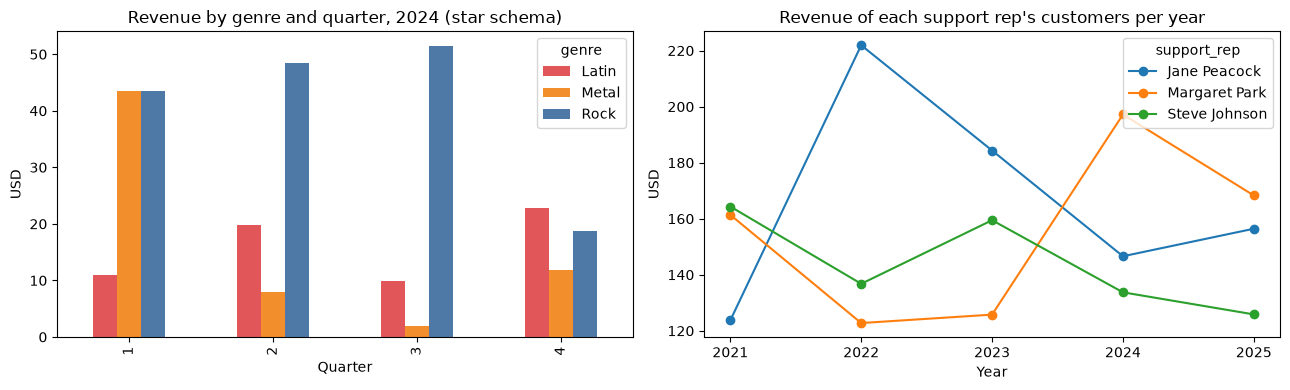

joins needed: star schema 2, normalised schema 3


In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
pivot.plot(kind="bar", ax=ax1, color=["#E15759", "#F28E2B", "#4E79A7"])
ax1.set(title="Revenue by genre and quarter, 2024 (star schema)", xlabel="Quarter", ylabel="USD")
by_rep = lq("""SELECT c.support_rep, d.year, sum(f.revenue) AS revenue FROM dw.fact_sales f
               JOIN dw.dim_customer c USING (customer_key) JOIN dw.dim_date d USING (date_key) GROUP BY 1, 2""")
by_rep.pivot(index="year", columns="support_rep", values="revenue").astype(float).plot(ax=ax2, marker="o")
ax2.set(title="Revenue of each support rep's customers per year", xlabel="Year", ylabel="USD")
ax2.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
plt.tight_layout()
plt.show()
print(f"joins needed: star schema {star_sql.count('JOIN')}, normalised schema {normalised_sql.count('JOIN')}")

The star query needs fewer joins, reads like the business question, and uses ready-made attributes (`quarter`, `is_weekend`) instead of date functions. In large warehouses, this simplicity also helps the query engine and BI tools (M09).

## 4. Slowly Changing Dimensions

Dimension attributes change: a customer moves to another city. Two common strategies:

| Type | Behaviour | History |
| :--- | :--- | :--- |
| **SCD type 1** | overwrite the old value | lost: old sales now show the new city |
| **SCD type 2** | close the old row (`valid_to`) and insert a new row with a new surrogate key | kept: each sale points to the version that was valid at the time |

The cell applies a type 2 change to one customer.

In [5]:
run("""
ALTER TABLE dw.dim_customer ADD COLUMN valid_from date NOT NULL DEFAULT '2021-01-01',
                            ADD COLUMN valid_to date NOT NULL DEFAULT '9999-12-31',
                            ADD COLUMN is_current boolean NOT NULL DEFAULT true;
UPDATE dw.dim_customer SET valid_to = '2024-06-30', is_current = false WHERE customer_source_id = 1;
INSERT INTO dw.dim_customer (customer_key, customer_source_id, customer_name, city, country, company, support_rep,
                             valid_from, valid_to, is_current)
SELECT (SELECT max(customer_key) + 1 FROM dw.dim_customer), customer_source_id, customer_name, 'Curitiba', country,
       company, support_rep, '2024-07-01', '9999-12-31', true
FROM dw.dim_customer WHERE customer_source_id = 1
""")
lq("SELECT customer_key, customer_source_id, customer_name, city, valid_from, valid_to, is_current "
   "FROM dw.dim_customer WHERE customer_source_id = 1 ORDER BY valid_from")

,customer_key,customer_source_id,customer_name,city,valid_from,valid_to,is_current
0,1,1,Luís Gonçalves,São José dos Campos,2021-01-01,2024-06-30,False
1,60,1,Luís Gonçalves,Curitiba,2024-07-01,9999-12-31,True


New sales after 1 July 2024 would reference the new key, so reports by city stay correct for both periods.

*Insight: Model analytics around business processes: declare the grain of each fact table, keep measures in facts and descriptions in dimensions, and give every dimension a date dimension partner. Most BI tools, dbt projects and cloud warehouses expect this shape.*

## Real-World Use Case or Analogy

A star schema is like a **sales ledger with reference books**. The ledger (fact table) has one line per sale with the numbers and short codes. The reference books (dimensions) explain each code: who the customer is, which product, which day of the week, which campaign. To answer a new question, you only open a different reference book.

Data warehouses in retail, banking and telecom are built as star schemas. Modern tools (dbt, M11; Spark, M13; Power BI and Superset, M09) still follow Kimball's design, often with a "wide table" built on top for convenience.